In [112]:
from ngsolve import *

from ngsolve.webgui import Draw
from netgen.csg import *

from netgen.occ import *
from netgen.meshing import IdentificationType

import numpy as np
import matplotlib.pyplot as plt

In [113]:
box_width = 1000
sphere_radius = 15

maxh = 50


vacuum = Box(Pnt(0,0,0), Pnt(box_width, box_width, box_width))

#sphere = Box(Pnt(0, 0, 0.5*box_width), Pnt(0.5*box_width, 0.5*box_width, 0.5*box_width + sphere_radius))

sphere = Sphere(Pnt(0.5*box_width, 0.5*box_width, 0.5*box_width), sphere_radius)

test_surface = Box(Pnt(0,0,0.25*box_width), Pnt(box_width, box_width, 0.35*box_width))



vacuum -= sphere

vacuum -= test_surface

vacuum.mat("vac");

sphere.mat("sph");

test_surface.mat("vac");


vacuum.faces.Min(X).name = "b0"
vacuum.faces.Max(X).name = "b1"
vacuum.faces.Min(Y).name = "b2"
vacuum.faces.Max(Y).name = "b3"
vacuum.faces.Min(Z).name = "b4"
vacuum.faces.Max(Z).name = "b5"

geo = OCCGeometry([vacuum, sphere, test_surface])


mesh = Mesh(geo.GenerateMesh(maxh=maxh)).Curve(3)

In [114]:
Draw(mesh)

WebGuiWidget(layout=Layout(height='500px', width='100%'), value={'gui_settings': {}, 'ngsolve_version': '6.2.2…

BaseWebGuiScene

In [115]:
eps_dict = {"vac" : 1.0 , "sph" : 1.0}

In [116]:
bound_dict = {'b0' :0, 'b1' :0, 'b2' :0, 'b3' :0, 'b4' :0, 'b5' :0}
charge = 0.01

fes = H1(mesh, order=2, dirichlet="b0|b1|b2|b3|b4|b5")   

gfu  = GridFunction(fes)
gfud = mesh.BoundaryCF( bound_dict, default=0)
gfu.Set(gfud, BND)

fesQ   = L2(mesh, order=2, definedon=mesh.Materials("sph"))

gfQ    = GridFunction(fesQ)
gfQ.Set(charge)

print ("ndof=", fes.ndof)

ndof= 56509


In [117]:
Integrate(gfQ, mesh=mesh.Materials("sph"))

141.394733276348

In [118]:
pow(sphere_radius,3) * (4/3)*np.pi * 0.01

141.3716694115407

In [119]:
Draw(gfQ, mesh.Materials("sph"))

WebGuiWidget(layout=Layout(height='500px', width='100%'), value={'gui_settings': {}, 'ngsolve_version': '6.2.2…

BaseWebGuiScene

In [120]:
epsr = mesh.MaterialCF( eps_dict )


u, v = fes.TnT()
a = BilinearForm(epsr * grad(u) * grad(v) * dx).Assemble() 
gfu  = GridFunction(fes)



In [121]:
Draw(gfu)

WebGuiWidget(layout=Layout(height='500px', width='100%'), value={'gui_settings': {}, 'ngsolve_version': '6.2.2…

BaseWebGuiScene

In [122]:

f   = LinearForm( gfQ * v * dx("sph")).Assemble()


inv = a.mat.Inverse(freedofs=fes.FreeDofs(), inverse="sparsecholesky")

res = (a.mat * gfu.vec - f.vec).Evaluate()

gfu.vec.data -= inv * res


In [123]:
Draw(gfu)

WebGuiWidget(layout=Layout(height='500px', width='100%'), value={'gui_settings': {}, 'ngsolve_version': '6.2.2…

BaseWebGuiScene

In [124]:
center = np.array([0.5*box_width, 0.5*box_width, 0.5*box_width])
R = sphere_radius

rvals = np.linspace(R, box_width/2, 200)  # extend into vacuum

phivals = []
for r in rvals:
    p = center + np.array([r, 0, 0])  # x-direction from center
    phivals.append(gfu(mesh(*p)))

In [128]:
def phi_analytical (r, q, esp_0 = 1):
    return q/(4 * np.pi * esp_0 * r)

In [129]:
phivals_analytical = phi_analytical(rvals, 4/3 * np.pi * sphere_radius ** 3 * charge)

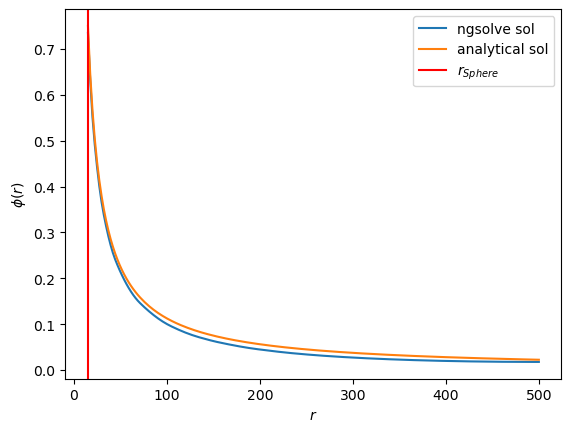

In [135]:
plt.plot(rvals, phivals, label='ngsolve sol')
plt.plot(rvals, phivals_analytical, label='analytical sol')
plt.axvline(sphere_radius, color='red', label='$r_{{Sphere}}$')
plt.xlabel('$r$')
plt.ylabel('$\\phi(r)$')
plt.legend()